# PopFrame: Анализ транспортной связанности и доступности субъекта Российской Федерации, оценка роли опорных населенных пунктов с использованием искусственного интеллекта 


**Цель:** исследовать систему расселения Ленинградской области, построить агломерации
и зоны опорных пунктов, сравнить результаты при изменении населения и времени доступности.

Модель региона загружается из файла **`examples/data/Ленинградская область.pickle`**.
Откройте ноутбук из корня репозитория и выберите ядро Python из `.venv`.
Он содержит готовую модель: границу региона, населённые пункты и матрицу времени между ними. Гексагональная сетка создаётся в ноутбуке.

**Порядок работы:** запускайте ячейки сверху вниз кнопкой ▶ или сочетанием Shift+Enter.
Необязательный раздел самостоятельной подготовки данных из OSM пропустите,
если работаете с готовой моделью.
Дождитесь окончания текущей ячейки. Меняйте параметры в начале соответствующего расчёта: матрица — раздел 2,
агломерации — раздел 4, сценарии — раздел 5, опорные пункты — раздел 6, территория — раздел 7.
После изменения параметров заново выполните следующие ячейки. При перезапуске
ядра повторите импорт и загрузку данных.

**Содержание**

1. Подготовка среды.
2. Загрузка данных: необязательная сборка из OSM и загрузка готовой модели.
3. Схема расселения.
4. Агломерации.
5. Сценарии изменения населения и времени доступности.
6. Выбор опорных пунктов и построение их зон.
7. Оценка расположения территории и профилей развития.
8. Анализ землепользования.
8. Сохранение результатов.

PopFrame помогает исследовать пространственные связи между населёнными пунктами,
сравнивать варианты развития и представлять результаты в таблицах и на картах.


## 1. Подготовка среды
### Установка библиотеки
Запустите ноутбук из корня репозитория PopFrame в Jupyter или VS Code.
Выберите ядро Python из `.venv`. Следующая ячейка устанавливает локальную библиотеку
и зависимости для ноутбуков; если они уже установлены, её можно пропустить.
После первой установки при необходимости перезапустите ядро и продолжите с импорта.


In [ ]:
# Выполните один раз, если зависимости ноутбука ещё не установлены.
%pip install -e ".[notebook]"

## 2. Загрузка данных

### Инструменты для загрузки
`Path` помогает указать расположение файла, а `Region` загружает модель региона.
Остальные инструменты подключим по мере выполнения соответствующих разделов.

In [1]:
from pathlib import Path  # Работа с путями к файлам.
from popframe.models.region import Region  # Загрузка и подготовка модели региона.

### Подготовка данных из OSM

**Если модель уже подготовлена, перейдите к «Загрузка модели».**
Ячейки ниже нужны тем, кто хочет самостоятельно собрать новую модель Ленинградской
области: границу, населённые пункты, дорожный граф и матрицу времени в пути.
Ваша готовая модель загружается дальше обычным способом.

Для сборки используется модуль `popframe.preprocessing.data_loader` из локальной библиотеки.

Загрузка идёт через Overpass, граница определяется через Nominatim. Серверы могут быть
недоступны: загрузчик повторяет временные ошибки и сохраняет завершённые этапы в
`cache/osm` в корне проекта. После сбоя повторите соответствующую ячейку.
Сборка всей области может занять длительное время.


In [2]:
from IPython.display import display
from popframe.preprocessing.data_loader import RegionDataLoader, build_region, save_region

osm_loader = RegionDataLoader({"state": "Ленинградская область", "country": "Россия"})

#### 1. Граница региона
Загрузчик исправляет геометрию границы и выбирает локальную проекцию UTM.
Расстояния в этой проекции измеряются в метрах.

In [ ]:
osm_boundary = osm_loader.load_boundary()
print("Рабочая проекция:", osm_boundary.crs)

#### 2. Населённые пункты и население
Загружаем именованные узлы OSM с тегами `city`, `town`, `village`, `hamlet`,
`isolated_dwelling` внутри границы. Запросы разбиваются на участки;
успешно загруженные участки используются при повторном запуске.
ID пунктов соответствуют ID узлов OSM.

In [ ]:
osm_towns = osm_loader.load_towns()
display(osm_towns[["id", "name", "population"]].head(10))
print("Пунктов без населения:", osm_towns.population.isna().sum())
display(osm_towns.loc[osm_towns.population.isna(), ["id", "name"]])

Население берётся из тега `population`, который есть не у всех пунктов.
Перед сборкой модели дополните пропуски по проверенному источнику: неизвестное
население не заменяется нулём. Проверьте также актуальность заполненных значений.

Пока остаются пропуски населения, завершающая ячейка сборки сообщит об ошибке.

#### 3. Дорожный граф
Загружаем автомобильные дороги с буфером 20 км вокруг региона, включая дороги
внутри внутренних отверстий его границы (например, Санкт-Петербург).
Время проезда оценивается по длине дорог и ограничениям скорости из OSM;
при отсутствии ограничений используется оценка по типу дороги. Пробки не учитываются.

In [ ]:
osm_graph = osm_loader.load_graph()
print("Дорожных узлов:", osm_graph.number_of_nodes(), "Рёбер:", osm_graph.number_of_edges())

#### 4. Матрица времени и единая модель pickle
Привязываем пункты к ближайшим дорожным узлам (не дальше 2 км), рассчитываем
матрицу времени в минутах с учётом направлений движения и собираем `Region`.
Бесконечность в матрице означает отсутствие автомобильного маршрута.
Матрица содержит все пары пунктов, поэтому расчёт требует времени и памяти.

Результат — один файл **`Ленинградская область_osm.pickle`** в текущей директории
(корне проекта). Существующий файл с таким именем не перезаписывается.

Для анализа собранной модели укажите её путь в разделе «Загрузка модели»
и выберите ID исследуемых пунктов из её таблицы.


In [ ]:
osm_region = build_region(osm_boundary, osm_towns, osm_graph)
osm_model_path = save_region(osm_region, "Ленинградская область_osm.pickle")
print("Модель сохранена:", osm_model_path)

### Загрузка модели
Укажите расположение модели в следующей ячейке. Пути задаются относительно корня проекта.


In [4]:
# Ноутбук запускается из корня репозитория.
DATA_DIR = Path("examples/data")
MODEL_NAME = 'Ленинградская область.pickle'
MODEL_PATH = DATA_DIR / MODEL_NAME

if not MODEL_PATH.is_file():
    raise FileNotFoundError(f'Не найден {MODEL_PATH}. Запустите ноутбук из корня репозитория.')

region_source = Region.from_pickle(str(MODEL_PATH))
print('Модель загружена:', MODEL_PATH)

Модель загружена: examples/data/Ленинградская область.pickle


### Подготовка модели к анализу
`prepare_for_analysis()` проверяет геометрии, население и соответствие ID в матрице
и таблице пунктов. Метод создаёт рабочую копию в локальной проекции UTM (метры)
и определяет размерные категории пунктов по населению.

Параметр `repair_geometry=True` включает исправление самопересечений границы
с сохранением её площадных частей.

Матрица хранит **время в минутах**. Ноль на диагонали соответствует поездке пункта
в самого себя, бесконечность обозначает недостижимую пару.
После подготовки модель готова к построению карт и расчёту сценариев.


In [5]:
# Проверяем модель, исправляем геометрию границы и создаём рабочую копию в проекции с метрами.
region_model = region_source.prepare_for_analysis(repair_geometry=True)
towns = region_model.get_towns_gdf()  # Таблица населённых пунктов с геометрией.
boundary = region_model.region  # Полигон границы региона.
travel_times = region_model.accessibility_matrix  # Время между пунктами, минуты.
LOCAL_CRS = region_model.crs  # Система координат для пространственных расчётов.

print('Модель готова к анализу. Проекция:', LOCAL_CRS)

Модель готова к анализу. Проекция: EPSG:32636


### Знакомство с данными
Краткая сводка показывает состав модели, население, размер матрицы и систему координат. Ниже — пять крупнейших населённых пунктов и фрагмент матрицы 5 × 5. Строка матрицы — пункт отправления, столбец — пункт назначения; значения — минуты. На следующей карте показаны граница региона и все населённые пункты.


In [6]:
import pandas as pd

display(pd.DataFrame({
    'Показатель': ['Геометрий границы', 'Населённых пунктов', 'Население, чел.',
                   'Матрица доступности, минуты', 'Система координат'],
    'Значение': [len(boundary), len(towns), towns.population.sum(),
                 f'{travel_times.shape[0]} × {travel_times.shape[1]}', str(LOCAL_CRS)],
}))

print('Пять крупнейших населённых пунктов:')
display(towns[['id', 'name', 'population', 'level']].nlargest(5, 'population'))
print('Фрагмент матрицы доступности, минуты:')
display(travel_times.iloc[:5, :5])


,Показатель,Значение
0,Геометрий границы,1
1,Населённых пунктов,2930
2,"Население, чел.",1930440
3,"Матрица доступности, минуты",2930 × 2930
4,Система координат,EPSG:32636


Пять крупнейших населённых пунктов:


,id,name,population,level
1874,1874,Гатчина,94377,Средний город
1694,1694,Выборг,79850,Средний город
1548,1548,Мурино,78184,Средний город
1542,1542,Всеволожск,75660,Средний город
1546,1546,Сертолово,58802,Средний город


Фрагмент матрицы доступности, минуты:


,0,1,2,3,4
0,0.000,11.687,12.024,10.794,7.768
1,11.687,0.000,0.337,4.313,18.027
2,12.024,0.337,0.000,4.650,18.364
3,10.794,4.313,4.650,0.000,17.134
4,7.768,18.027,18.364,17.134,0.000


### Обзорная схема расселения


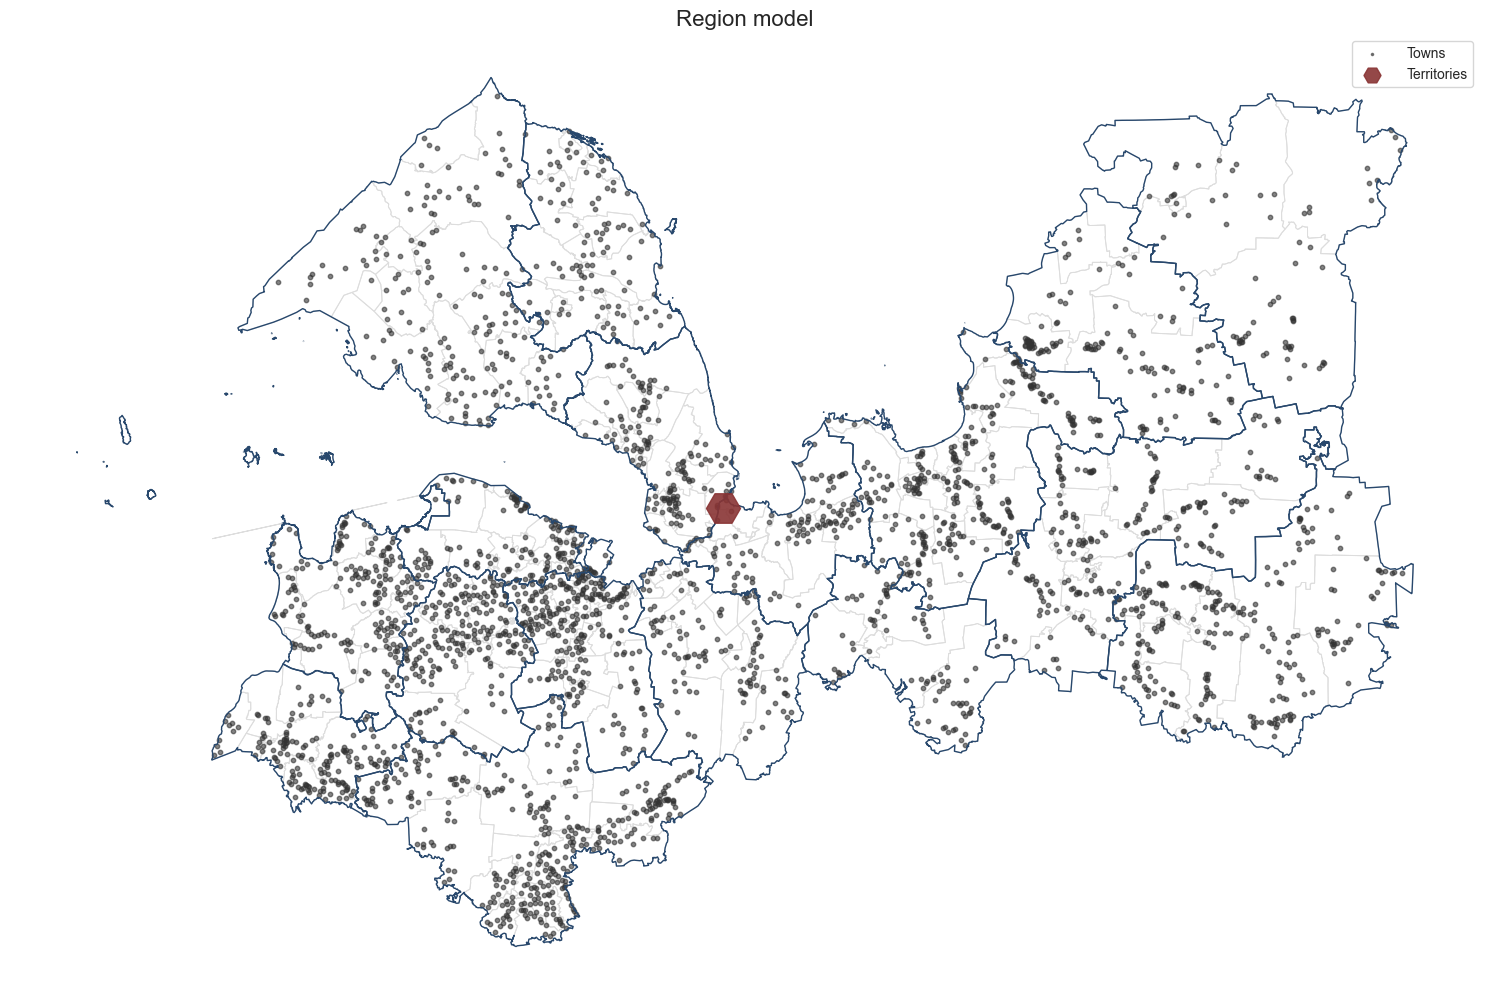

### Параметры просмотра матрицы доступности

- `MATRIX_TOWN_ID` — ID пункта отправления; в примере Гатчина (`1874`).
- `MATRIX_TIME` — порог времени для просмотра доступных пунктов, минуты.

Эти параметры управляют только следующей таблицей доступности.
Параметры агломераций задаются в разделе 4, сценариев — в разделе 5,
опорных пунктов — в разделе 6.


In [7]:
MATRIX_TOWN_ID = 1874  # Гатчина — пункт отправления для просмотра матрицы.
MATRIX_TIME = 80  # Порог времени для этой таблицы, минуты.

print(f'Пункт отправления: {towns.loc[MATRIX_TOWN_ID, "name"]} (ID {MATRIX_TOWN_ID})')


Пункт отправления: Гатчина (ID 1874)


### Чтение матрицы доступности
Строка исследуемого пункта показывает время **из него** в остальные пункты.
Столбец показывает время поездки в обратном направлении.
Матрица помогает найти доступные пункты и сравнить их транспортное положение.


In [8]:
# Берём время поездки из выбранного пункта во все остальные.
times_from_town = travel_times.loc[MATRIX_TOWN_ID]
# Оставляем пункты, доступные за MATRIX_TIME минут; copy() создаёт отдельную таблицу.
reachable = towns.loc[times_from_town.le(MATRIX_TIME)].copy()
# Сопоставляем значения времени с пунктами по ID.
reachable['Время, мин'] = times_from_town.reindex(reachable.index)
# Сортируем по времени и показываем 15 ближайших пунктов.
display(reachable[['name', 'population', 'Время, мин']].sort_values('Время, мин').head(15))
print(f'Доступно за {MATRIX_TIME} мин: {len(reachable)} пунктов, включая пункт отправления.')

,name,population,"Время, мин"
1874,Гатчина,94377,0.000
1974,Вайялово,415,3.567
2052,Пригородный,504,3.871
1972,Вайя,282,3.951
2055,Торфяное,1149,4.071
1986,Новое Мозино,300,4.213
1973,Ивановка,299,4.213
1969,Малое Верево,4245,4.599
1966,Малые Колпаны,461,4.742
2062,Сокколово,300,4.751


Доступно за 80 мин: 1103 пунктов, включая пункт отправления.


## 3. Схема расселения
### `PopulationFrame.build_circle_frame()`
**Вход:** модель региона с точками, населением и размерными категориями.
**Принцип:** вокруг каждой точки строится условный круг, радиус которого зависит
от корня из численности населения и категории.
**Результат:** слой полигонов, наглядно представляющий структуру расселения.

Размеры кругов помогают сопоставить населённые пункты и выделить крупные центры.
Для определения принадлежности пунктов к агломерациям используются их геометрии точек.

Цвета кругов обозначают размерные категории населённых пунктов: от жёлтых
сельских поселений до красных и фиолетовых городов. Категории приведены в легенде.


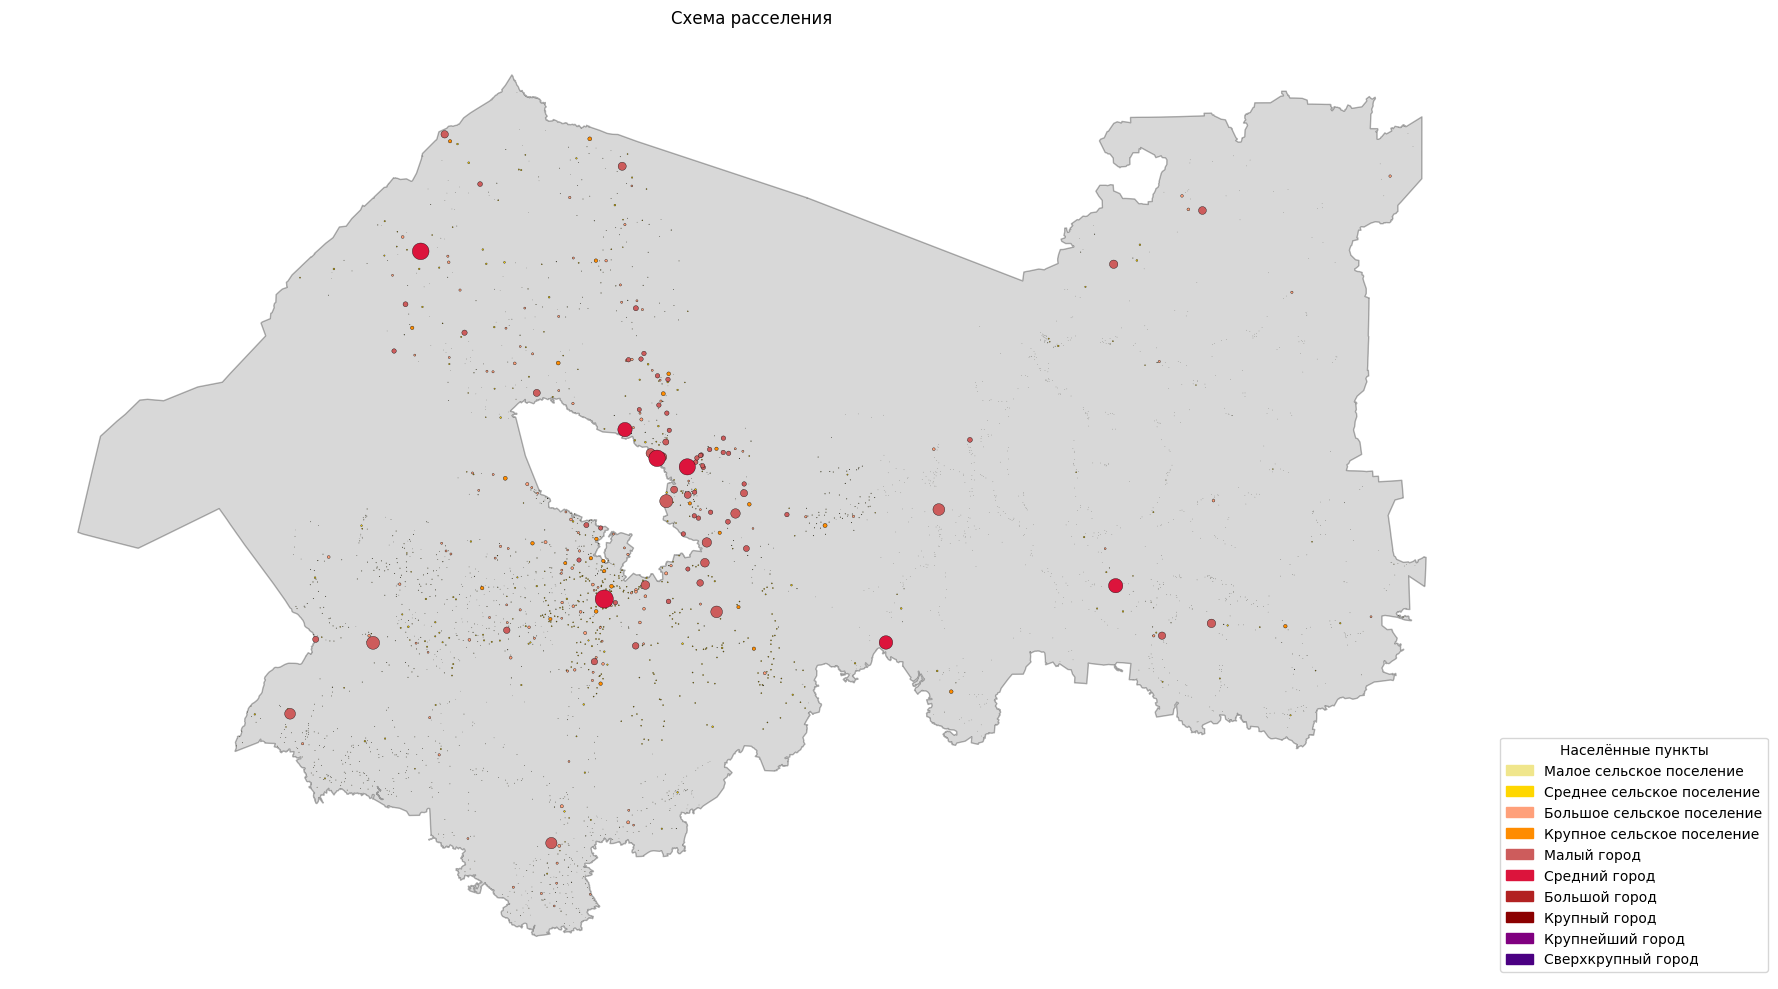

In [9]:
import matplotlib.pyplot as plt
from popframe.method.popuation_frame import PopulationFrame
from popframe.visualization import plot_settlement_scheme

# Строим круги, размер которых зависит от населения и категории пункта.
population_frame = PopulationFrame(region=region_model).build_circle_frame()
# Раскрашиваем круги по категориям и добавляем легенду.
plot_settlement_scheme(region_model, population_frame)
plt.tight_layout()
plt.show()

## 4. Агломерации
### `AgglomerationBuilder.get_agglomerations()`
**Вход:** населённые пункты, матрица времени и параметр `time` в минутах.
Метод выбирает центры по размерной категории и населению, находит доступные пункты,
строит вокруг них буферы по оставшемуся времени, объединяет пересечения
и формирует границы агломераций в пределах региона.

Порог `time` уменьшается на 10 минут при переходе к каждой следующей
размерной категории центров. Для перевода оставшегося времени в радиус буфера
используется коэффициент **400 м/мин**. Минимальное население центра — **15 000 человек**.

**Результат:** геометрия, центры (`core_cities`), население (`population`) и уровень
агломерации (`agglomeration_level`, 1–5), определяемый численностью населения.
Полученные слои позволяют сравнить масштаб агломераций, их центры и охват населённых пунктов.
### Параметры агломераций
`BASE_TIME` — базовый порог времени в минутах (не менее 50).
В разделе 5 он используется для сравнения сценариев с базовым расчётом.


In [10]:
BASE_TIME = 80  # Базовый порог времени для агломераций, минуты.


In [11]:
from popframe.method.agglomeration import AgglomerationBuilder

# Создаём объект для расчёта базового варианта агломераций.
base_builder = AgglomerationBuilder(region=region_model)
# Строим агломерации с базовым населением и базовым порогом времени.
base_agglomerations = base_builder.get_agglomerations(time=BASE_TIME)
# Определяем положение каждого пункта относительно агломераций.
base_status = base_builder.evaluate_city_agglomeration_status(towns, base_agglomerations)
# Выводим характеристики агломераций без длинного столбца геометрии.
display(base_agglomerations.drop(columns='geometry').head(15))
display(base_status[['name', 'population', 'agglomeration_status', 'agglomeration_level']].head(15))

,type,core_cities,population,agglomeration_level
0,Polycentric,"Бугры, Всеволожск, Гатчина, Кировск, Коммунар,...",1116875,4
1,Polycentric,"Выборг, Светогорск",129217,1
2,Polycentric,"Бокситогорск, Пикалево, Тихвин",105381,1
3,Polycentric,"Волхов, Кириши",102494,1
4,Polycentric,"Кингисепп, Сланцы",115479,1
5,Monocentric,Луга,58784,1
6,Polycentric,"Лодейное Поле, Подпорожье",44609,1
7,Monocentric,Приозерск,30441,1


,name,population,agglomeration_status,agglomeration_level
0,Болото,10,В агломерации,1
1,Большой Остров,68,В агломерации,1
2,Бор,1734,В агломерации,1
3,Бороватое,10,В агломерации,1
4,Бочево,10,В агломерации,1
5,Гостихино,10,В агломерации,1
6,Дмитрово,10,Вне агломерации,0
7,Дорогощи,9,Вне агломерации,0
8,Дороховая,10,В агломерации,1
9,Жилоток,10,В агломерации,1


### Карта агломераций и принадлежность пунктов
`evaluate_city_agglomeration_status()` определяет, пересекает ли **точка** пункта
полигон агломерации, и добавляет статус: центр, участник или вне агломерации.
Таблицу статусов можно использовать для сравнения сценариев по одним и тем же ID.

Функция `plot_settlement_scheme()` использует одинаковые цвета и легенды для всех сценариев.

Уровни агломераций показаны голубым, сиреневым, оливковым, светло-жёлтым
и тёмно-зелёным цветами. Населённые пункты сохраняют цвета своих размерных категорий.


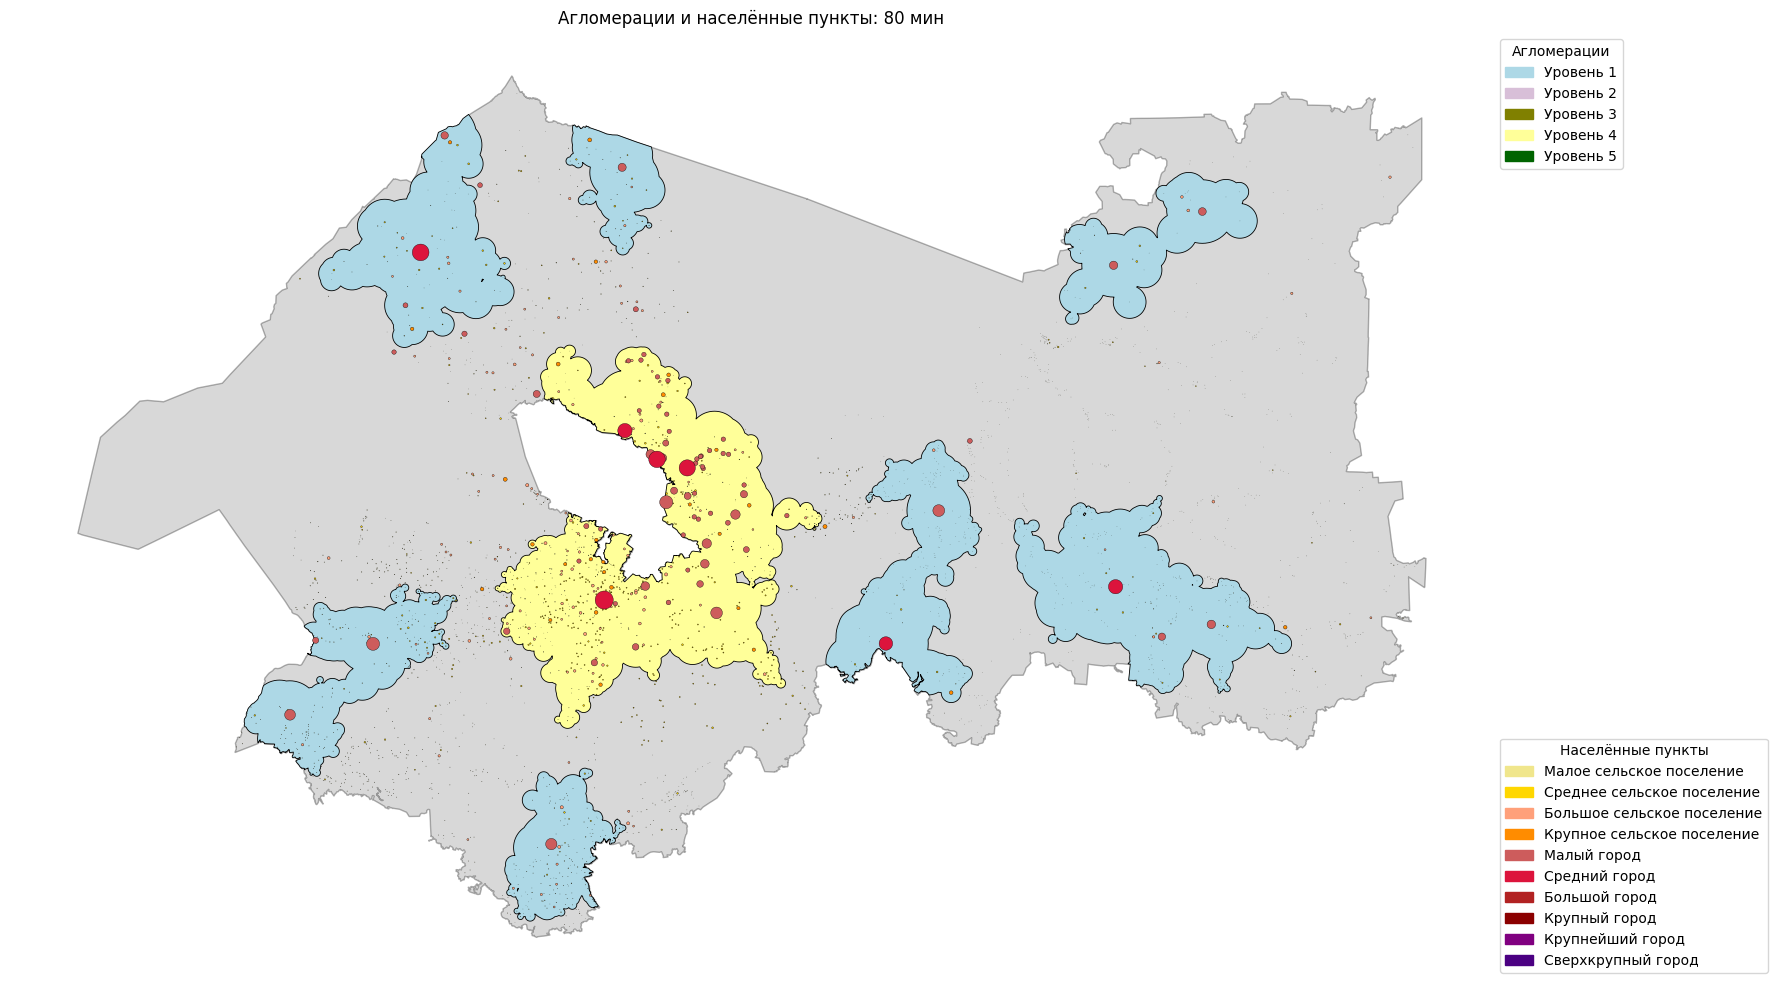

In [12]:
# Совмещаем агломерации и круги населения на одной карте.
plot_settlement_scheme(region_model, population_frame, base_agglomerations,
                       title=f'Агломерации и населённые пункты: {BASE_TIME} мин')
plt.tight_layout()
plt.show()

## 5. Сценарии: меняем один фактор
### Сценарий А — изменение населения
Передаём `update_df`: таблицу новых значений населения с ID пунктов в индексе.
Библиотека пересчитывает размерную категорию и строит агломерации с обновлёнными данными.
Так можно проследить, как рост выбранного пункта влияет на систему расселения
при неизменной матрице времени поездок.

Для каждого сценария создаём отдельный `AgglomerationBuilder`.
Базовые результаты сохраняем для последующего сравнения.

В примере, население Гатчины (`ID = 1874`) задаётся равным **300 000 человек**. Пересчитываем агломерации и круги
населённых пунктов, затем сопоставляем карты в той же палитре.
#### Параметры сценария А
`TOWN_ID` — ID пункта, население которого меняем; `SCENARIO_POPULATION` — новое население.
В следующей ячейке формируется `update_df`. Порог `BASE_TIME` берётся из раздела 4:
в этом сценарии меняем только население.


In [35]:
import pandas as pd

TOWN_ID = 1874  # Гатчина — пункт, население которого меняем в сценарии А.
SCENARIO_POPULATION = 300_000  # Новое население, человек.

selected_town_id = TOWN_ID
selected_town = towns.loc[selected_town_id]
scenario_population = SCENARIO_POPULATION
print(f'Сценарий А: {selected_town["name"]} (ID {selected_town_id})')
print(f'Население: {selected_town.population:,} → {scenario_population:,} чел.')

# update_df: индекс — ID пункта, population — новое население.
update_df = pd.DataFrame({'population': [scenario_population]}, index=[selected_town_id])
display(update_df)


Сценарий А: Гатчина (ID 1874)
Население: 94,377 → 300,000 чел.


,population
1874,300000


In [36]:
# Получаем пункты с обновлённым населением и пересчитанными категориями.
scenario_towns = region_model.get_update_towns_gdf(update_df)
# Для сценария используем отдельный расчётный объект.
population_builder = AgglomerationBuilder(region=region_model)
# Перестраиваем агломерации с новым населением при прежнем пороге времени.
population_agglomerations = population_builder.get_agglomerations(
    update_df=update_df, time=BASE_TIME)
# Пересчитываем принадлежность пунктов к полученным агломерациям.
population_status = population_builder.evaluate_city_agglomeration_status(scenario_towns, population_agglomerations)
# Меняем размеры и категории кругов на карте в соответствии с новым населением.
population_frame_scenario = PopulationFrame(region=region_model).build_circle_frame(update_df)

# Сопоставляем население и категорию выбранного пункта до и после изменения.
display(pd.DataFrame({
    'База': towns.loc[selected_town_id, ['name', 'population', 'level']],
    'Сценарий А': scenario_towns.loc[selected_town_id, ['name', 'population', 'level']],
}))

,База,Сценарий А
name,Гатчина,Гатчина
population,94377,300000
level,Средний город,Крупный город


### Сценарий Б — другой порог времени
Используем базовое население и меняем параметр `time`.
Сравнение показывает, как выбранный порог влияет на границы агломераций
и количество охваченных населённых пунктов.
`SCENARIO_TIME` задаётся в следующей ячейке, в минутах.


In [37]:
SCENARIO_TIME = 100  # Альтернативный порог времени для сценария Б, минуты.

# В сценарии Б используем базовое население и увеличенный порог времени.
time_builder = AgglomerationBuilder(region=region_model)
time_agglomerations = time_builder.get_agglomerations(time=SCENARIO_TIME)
# Определяем статусы пунктов при новом охвате агломераций.
time_status = time_builder.evaluate_city_agglomeration_status(towns, time_agglomerations)

### Сравнение результатов
Сопоставим количество полигонов, число пунктов внутри агломераций
и суммарное население охваченных пунктов. Население суммируется по уникальным ID.

Все карты используют одну шкалу уровней. Таблицы показывают изменения относительно
базы и помогают связать результат с изменением выбранного параметра.

,Полигонов,Пунктов внутри,"Население пунктов внутри, чел."
Базовый сценарий,8,1487,1703280
А: население,6,1635,1945822
Б: время,2,2471,1901579


,Полигонов,Пунктов внутри,"Население пунктов внутри, чел."
Изменение относительно базы,,,
Базовый сценарий,0,0,0
А: население,-2,148,242542
Б: время,-6,984,198299


,name,population,Базовый сценарий,А: население,Б: время
6,Дмитрово,10,Вне агломерации,Вне агломерации,В агломерации
7,Дорогощи,9,Вне агломерации,Вне агломерации,В агломерации
12,Зубакино,9,Вне агломерации,Вне агломерации,В агломерации
24,Половное,10,Вне агломерации,Вне агломерации,В агломерации
26,Рудная Горка,10,Вне агломерации,Вне агломерации,В агломерации
27,Савино,10,Вне агломерации,Вне агломерации,В агломерации
70,Бочатино,9,Вне агломерации,Вне агломерации,В агломерации
74,Гагрино,10,Вне агломерации,Вне агломерации,В агломерации
76,Головково,10,Вне агломерации,Вне агломерации,В агломерации
80,Дудинское,10,Вне агломерации,Вне агломерации,В агломерации


Пунктов, сменивших статус хотя бы в одном сценарии: 988


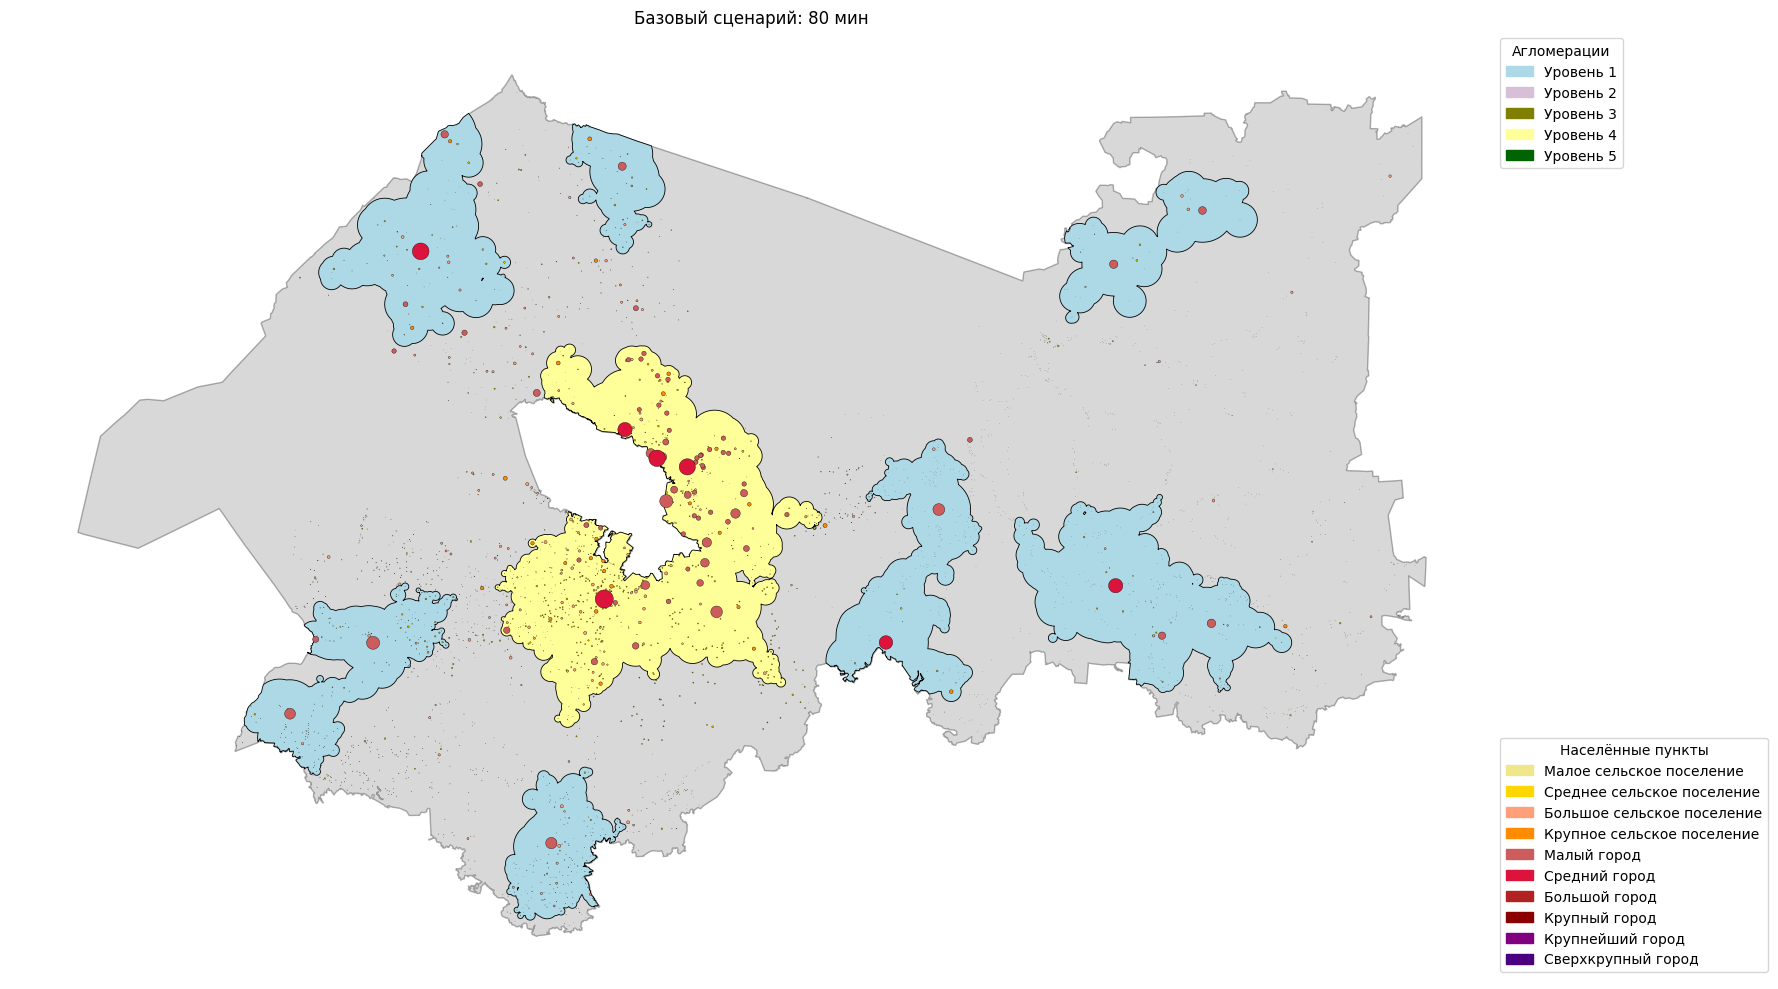

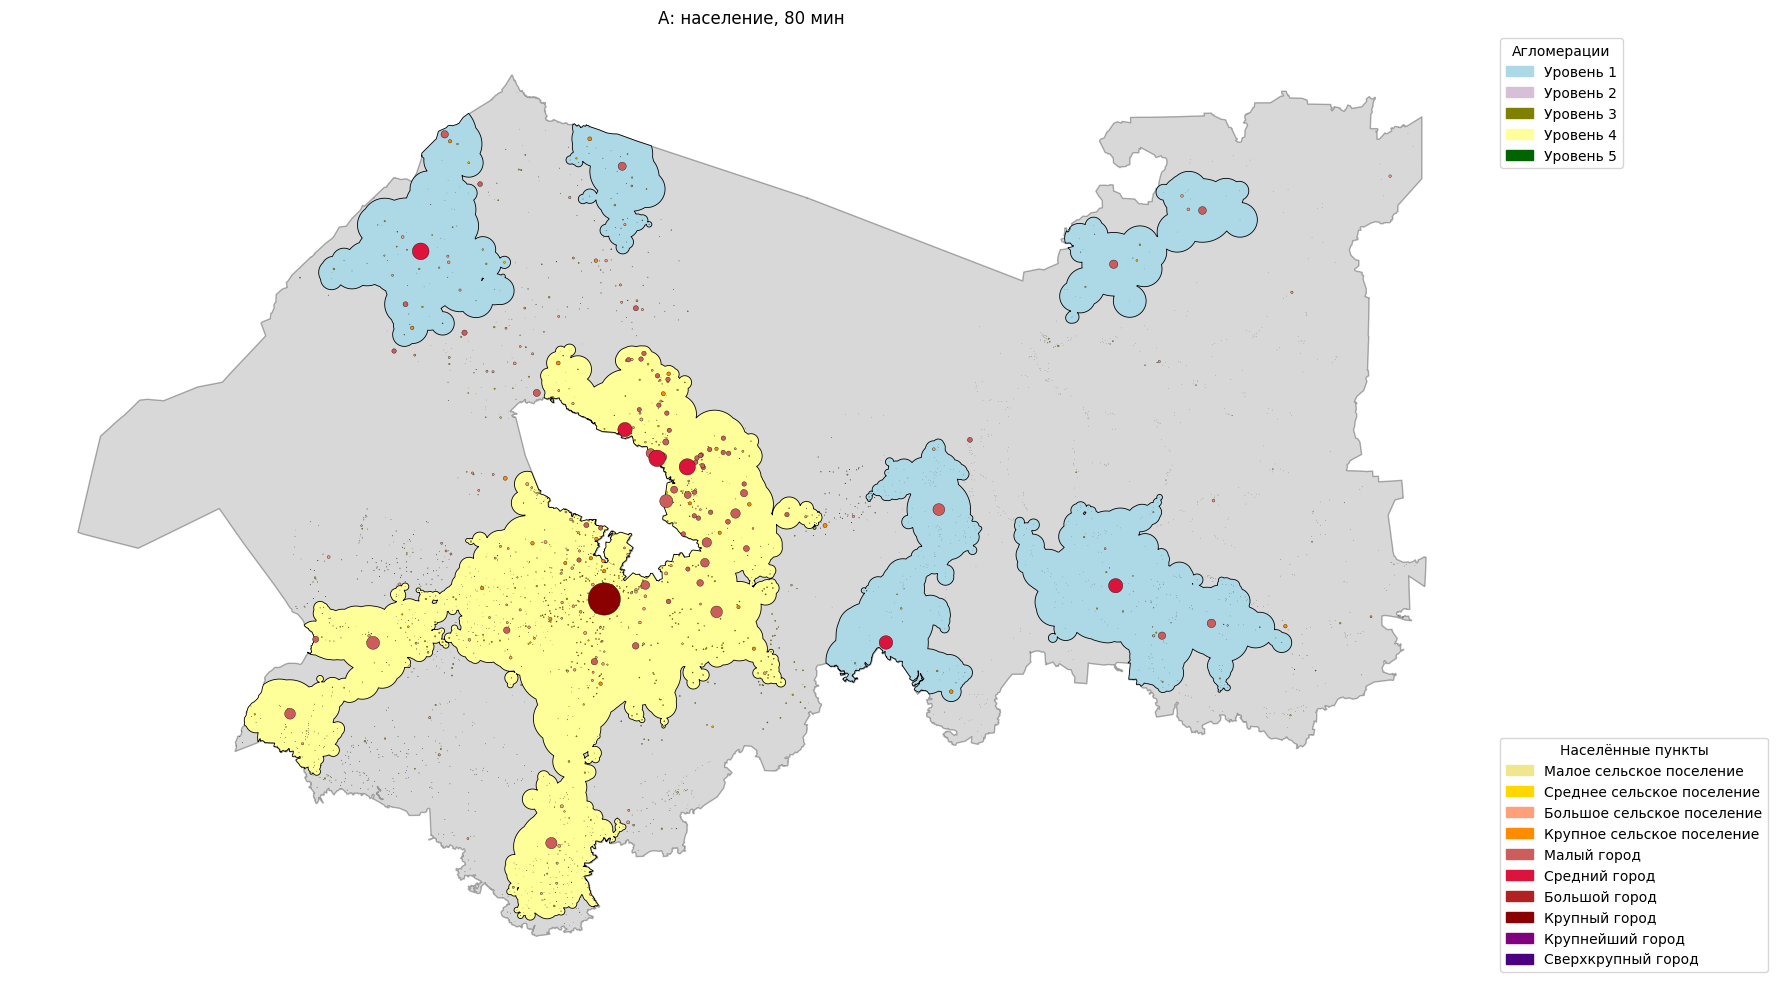

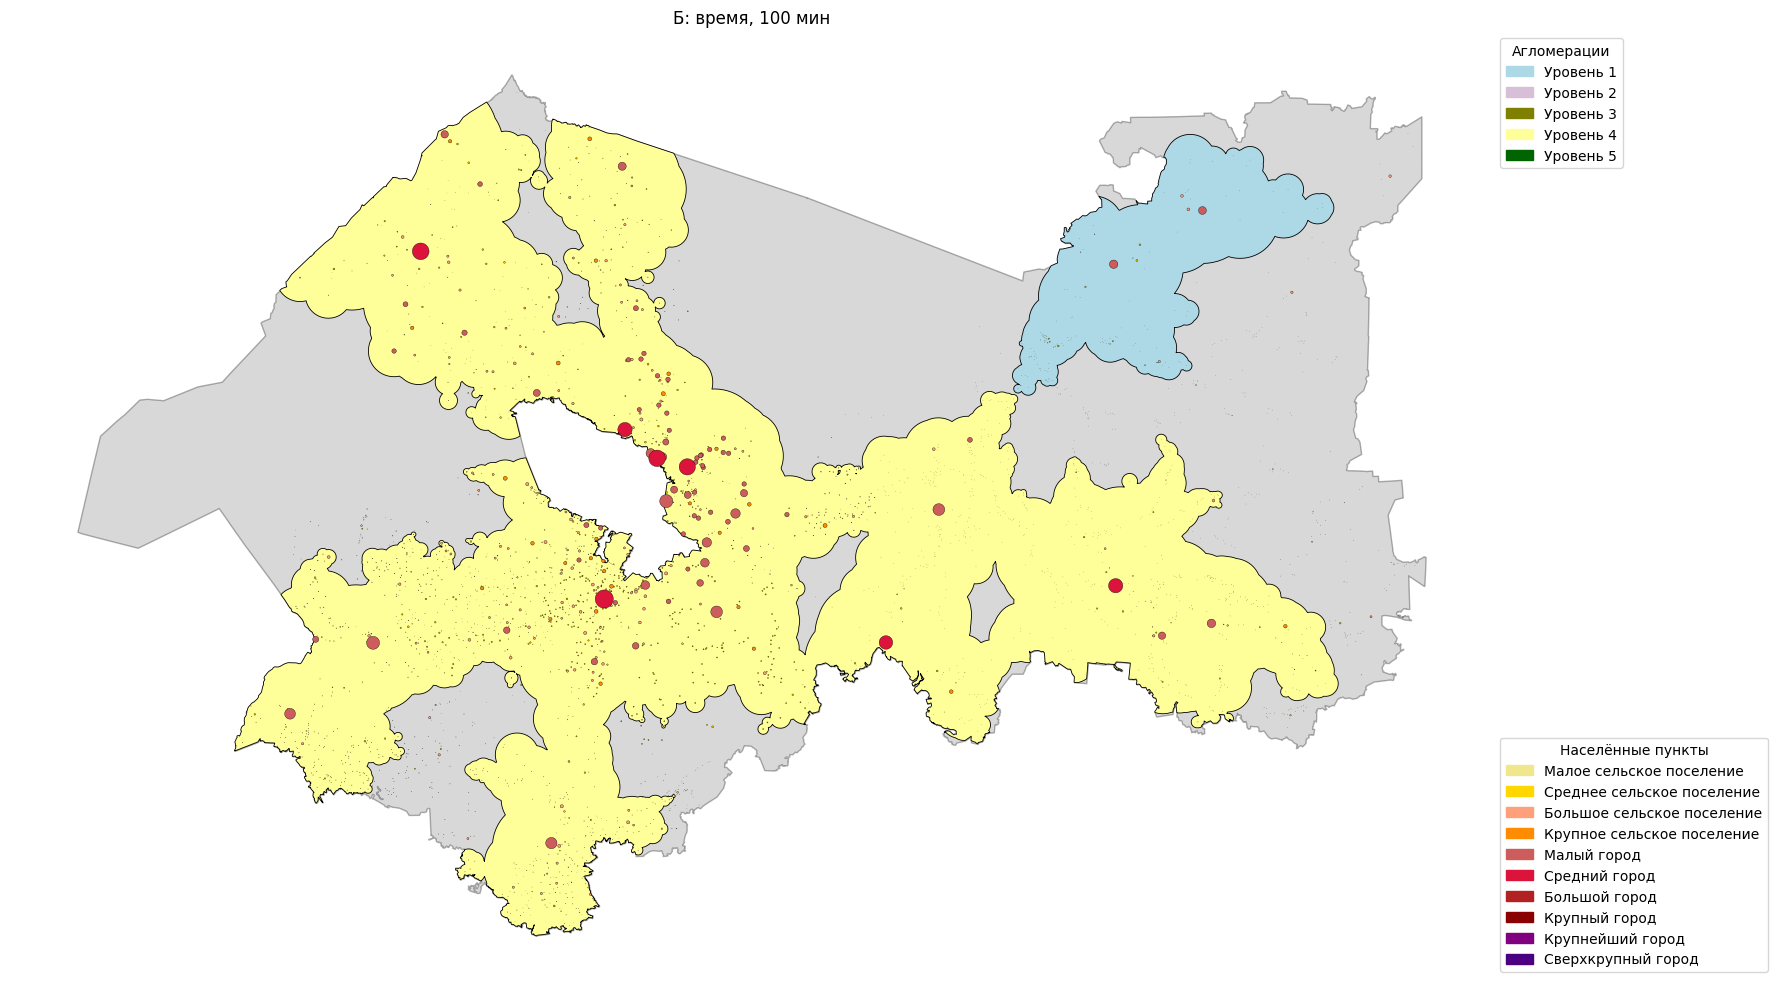

In [38]:
# Функция собирает показатели сценария: полигоны, пункты и население внутри агломераций.
def summarize_scenario(areas, status):
    # Отмечаем строки пунктов, принадлежащих агломерациям.
    inside = status['agglomeration_status'].ne('Вне агломерации')
    return {'Полигонов': len(areas), 'Пунктов внутри': int(inside.sum()),
            'Население пунктов внутри, чел.': int(status.loc[inside, 'population'].sum())}

# Собираем три сценария в таблицу; .T размещает сценарии по строкам.
scenario_summary = pd.DataFrame({
    'Базовый сценарий': summarize_scenario(base_agglomerations, base_status),
    'А: население': summarize_scenario(population_agglomerations, population_status),
    'Б: время': summarize_scenario(time_agglomerations, time_status),
}).T
display(scenario_summary)
# Вычитаем базовые значения, чтобы показать величину изменений.
display(scenario_summary.subtract(scenario_summary.loc['Базовый сценарий']).rename_axis('Изменение относительно базы'))

# Сопоставляем статусы одного и того же пункта в трёх сценариях по его ID.
status_comparison = towns[['name', 'population']].copy()
status_comparison['Базовый сценарий'] = base_status['agglomeration_status']
status_comparison['А: население'] = population_status['agglomeration_status']
status_comparison['Б: время'] = time_status['agglomeration_status']
# Находим пункты, чей статус изменился хотя бы в одном сценарии; | означает «или».
changed = status_comparison['Базовый сценарий'].ne(status_comparison['А: население']) | status_comparison['Базовый сценарий'].ne(status_comparison['Б: время'])
display(status_comparison.loc[changed].head(20))
print('Пунктов, сменивших статус хотя бы в одном сценарии:', int(changed.sum()))

# По очереди рисуем три сценария с одинаковыми цветами категорий и легендами.
for areas, circles, title in zip(
        [base_agglomerations, population_agglomerations, time_agglomerations],
        [population_frame, population_frame_scenario, population_frame],
        [f'Базовый сценарий: {BASE_TIME} мин', f'А: население, {BASE_TIME} мин', f'Б: время, {SCENARIO_TIME} мин']):
    plot_settlement_scheme(region_model, circles, areas, title=title)
    plt.tight_layout()
    plt.show()

## 6. Опорные населённые пункты
### `AnchorSettlementBuilder.get_anchor_settlement_boundaries()`
**Вход:** модель региона, слой точек с признаком `is_anchor_settlement`
и порог `time`. Признак позволяет задать исследуемый набор опорных пунктов.

Метод использует матрицу времени, строит и объединяет зоны доступности,
затем разделяет общие области, в том числе с помощью диаграммы Вороного.
Результат помогает сравнить пространственный охват разных наборов опорных пунктов.

### Источник перечня и соответствие модели
Используем перечень **27 опорных населённых пунктов Ленинградской области**,
приведённый в [постановлении Правительства Ленинградской области от 22.07.2025 № 642](https://lenoblpravo.ru/postanovlenie/2025/07/22/n-642/)
(приложение 3 к порядкам реновации образовательных организаций).
ID соответствуют населённым пунктам загруженной модели.
Перечень проверен 19.10.2026. ID относятся к этой модели, а не к ОКТМО или OSM.

**В модели доступны 26 из 27 пунктов.** Город **Сосновый Бор** отсутствует;
одноимённые деревни с ID `203` и `1817` в выборку не включены.
Отрадное, Волосово, Волхов и Кириши выбраны по ID именно городов,
чтобы не включить одноимённые деревни.

### Параметры опорных пунктов
В следующей ячейке `anchor_ids` содержит ID доступных опорных пунктов с их названиями.
`ANCHOR_TIME` — порог времени для построения их зон, в минутах.
Для своего сценария меняйте список и порог здесь, затем повторяйте расчёт ниже.
`is_anchor_settlement=True` получают выбранные ID; остальные — `False`.
Параметр времени задаёт расчётную зону и не определяет официальный статус пункта.

Цвет опорного пункта определяется его численностью населения: используем те же
размерные категории и палитру, что и на карте расселения. Диапазоны населения указаны
в легенде. Зоны показаны светло-голубым с тонкими границами.
На карте показаны только выбранные опорные пункты.


In [39]:
# 26 пунктов официального перечня, присутствующих в модели.
anchor_ids = [
    1874,  # Гатчина
    1542,  # Всеволожск
    1548,  # Мурино
    1546,  # Сертолово
    1553,  # Кудрово
    529,   # Отрадное (город)
    2815,  # Тосно
    526,   # Кировск
    259,   # Кингисепп
    # Сосновый Бор (город) в модели отсутствует.
    1694,  # Выборг
    1695,  # Высоцк
    1726,  # Приморск
    1747,  # Светогорск
    261,   # Ивангород
    350,   # Усть-Луга
    121,   # Бокситогорск
    128,   # Пикалево
    1060,  # Волосово (город)
    1261,  # Волхов (город)
    449,   # Кириши (город)
    630,   # Лодейное Поле
    2114,  # Луга
    911,   # Подпорожье
    1030,  # Приозерск
    2462,  # Сланцы
    2618,  # Тихвин
]
ANCHOR_TIME = 50  # Порог времени для зон опорных пунктов, минуты.

anchor_towns = towns.copy()
anchor_towns['is_anchor_settlement'] = anchor_towns.index.isin(anchor_ids)
print('Выбрано опорных пунктов:', int(anchor_towns['is_anchor_settlement'].sum()))
display(anchor_towns.loc[anchor_ids, ['id', 'name', 'population', 'is_anchor_settlement']])


Выбрано опорных пунктов: 26


,id,name,population,is_anchor_settlement
1874,1874,Гатчина,94377,True
1542,1542,Всеволожск,75660,True
1548,1548,Мурино,78184,True
1546,1546,Сертолово,58802,True
1553,1553,Кудрово,49079,True
529,529,Отрадное,25480,True
2815,2815,Тосно,39077,True
526,526,Кировск,25704,True
259,259,Кингисепп,47969,True
1694,1694,Выборг,79850,True


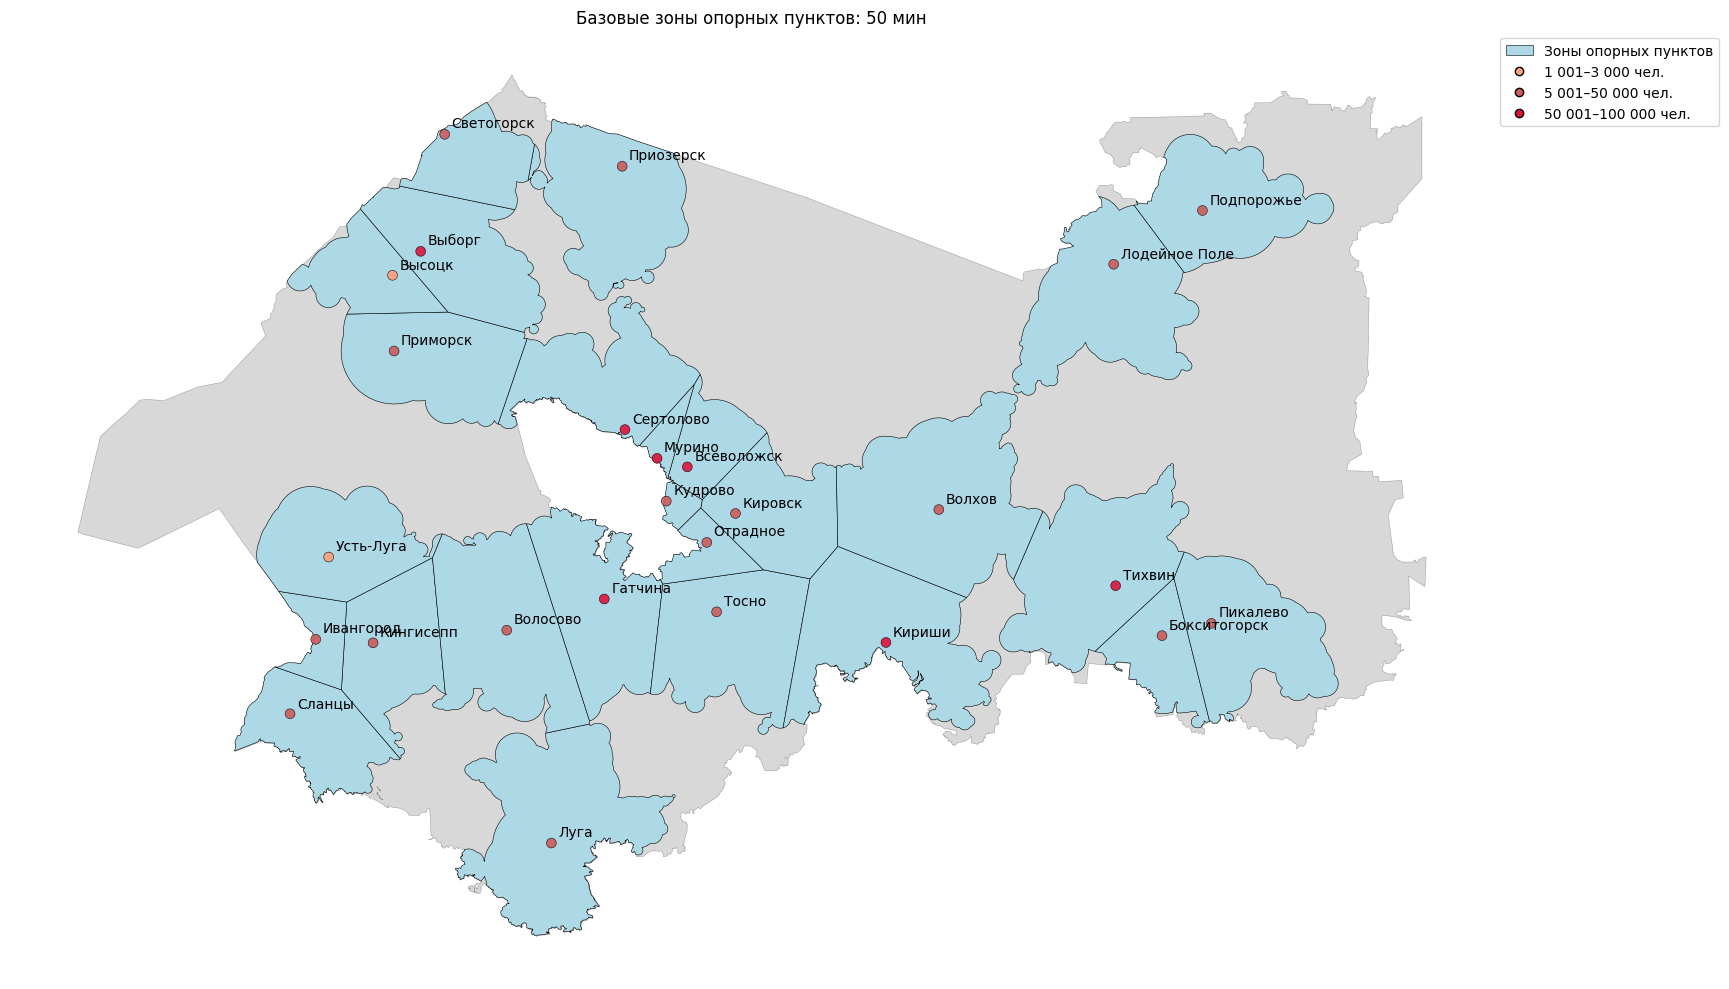

In [18]:
from popframe.method.anchor_settlement import AnchorSettlementBuilder
from popframe.visualization import plot_anchor_settlements

# Строим зоны выбранных опорных пунктов по порогу времени ANCHOR_TIME.
anchor_boundaries = AnchorSettlementBuilder(region=region_model).get_anchor_settlement_boundaries(
    towns=anchor_towns, time=ANCHOR_TIME)

# Раскрашиваем опорные пункты по населению, сохраняя общую палитру карт.
plot_anchor_settlements(region_model, anchor_boundaries,
                        anchor_towns.loc[anchor_towns['is_anchor_settlement']],
                        title=f'Базовые зоны опорных пунктов: {ANCHOR_TIME} мин',
                        color_by_population=True)
plt.tight_layout()
plt.show()

### Сценарий: время доступности больше на 15 минут
Сохраняем набор опорных пунктов и их население, увеличивая только порог времени.
При базовом значении 50 минут сценарий использует 65 минут.
Ниже строится отдельная карта с теми же цветами категорий населения.
Базовые зоны остаются в `anchor_boundaries`, сценарные — в `anchor_boundaries_scenario`.


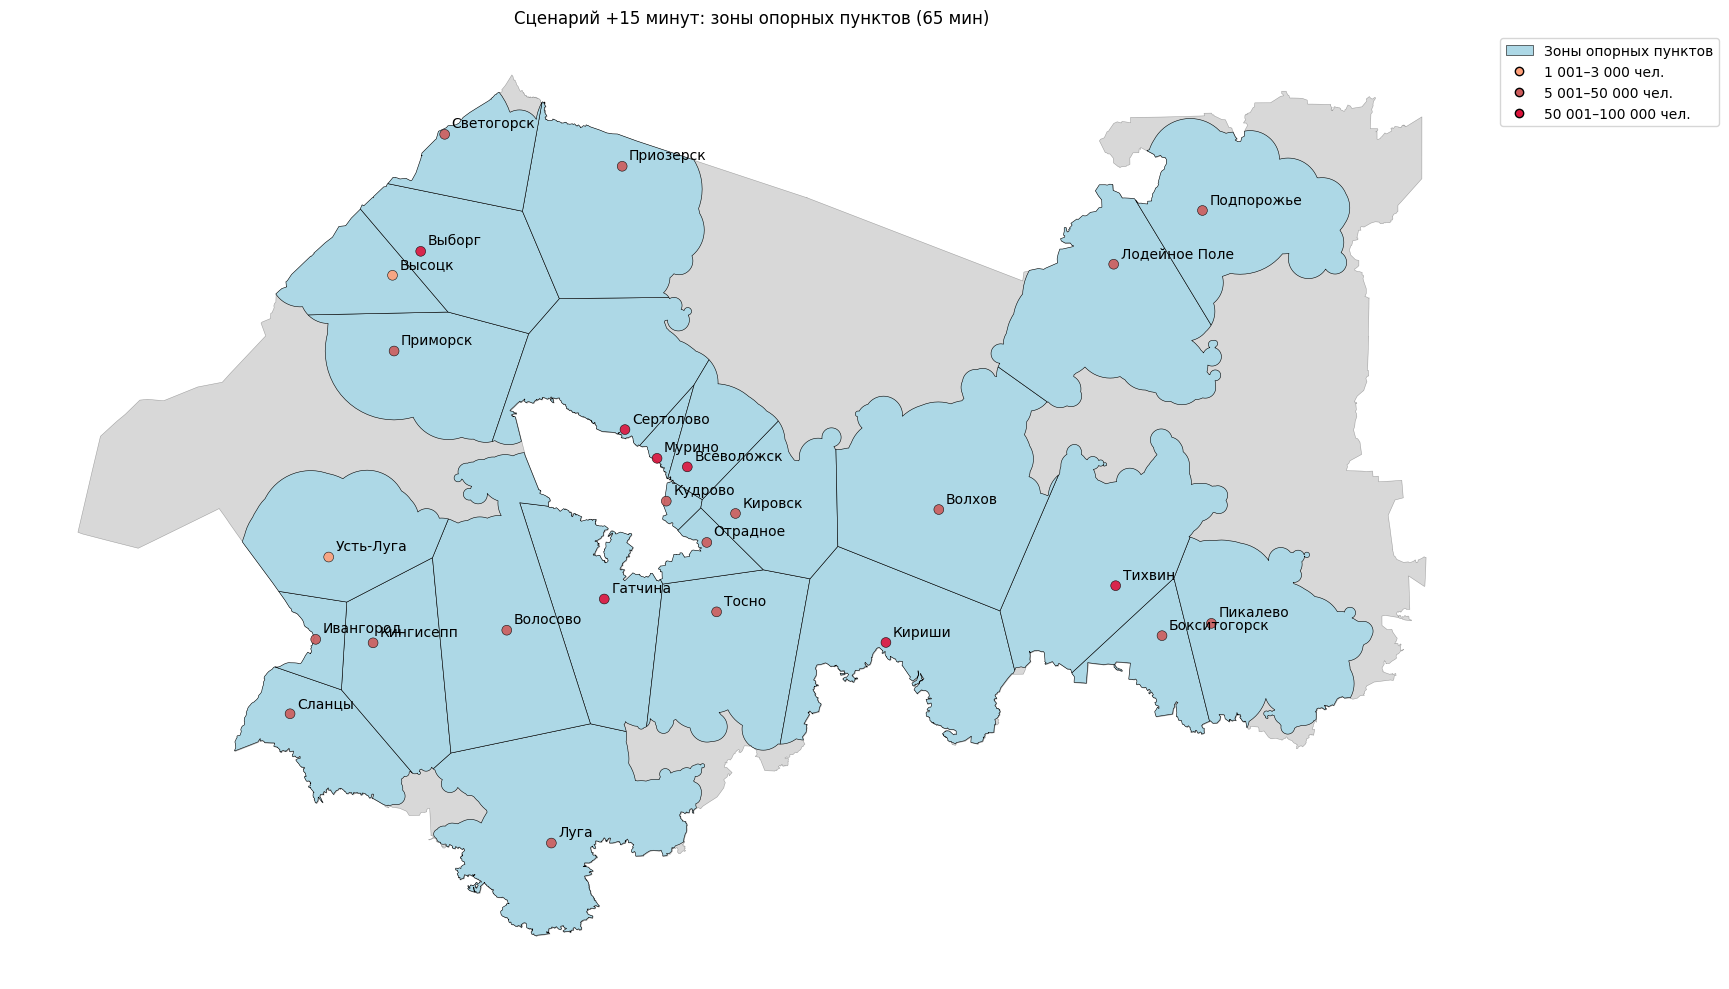

In [19]:
anchor_scenario_time = ANCHOR_TIME + 15  # Увеличиваем базовый порог на 15 минут.
anchor_boundaries_scenario = AnchorSettlementBuilder(region=region_model).get_anchor_settlement_boundaries(
    towns=anchor_towns, time=anchor_scenario_time,
)

plot_anchor_settlements(
    region_model, anchor_boundaries_scenario,
    anchor_towns.loc[anchor_towns['is_anchor_settlement']],
    title=f'Сценарий +15 минут: зоны опорных пунктов ({anchor_scenario_time} мин)',
    color_by_population=True,
)
plt.tight_layout()
plt.show()


## 7. Расположение выбранной территории
### Создание гексагональной сетки
`create_leningrad_hexagons()` строит сетку из 2148 гексагонов по адресам H3.
Каждый гексагон имеет стабильный числовой ID.
Готовые полигоны создаются при запуске ячейки в системе координат региона.

Сетка позволяет выбирать сопоставимые по масштабу территории для оценки их положения
в системе расселения. По умолчанию будем исследовать **гексагон 1632**.


In [20]:
from popframe.preprocessing.hex_grid import create_leningrad_hexagons

# Создаём гексагональную сетку в проекции региона.
hexagons = create_leningrad_hexagons(crs=LOCAL_CRS)
print('Создано гексагонов:', len(hexagons))

Создано гексагонов: 2148


### Интерактивная карта гексагонов
`GeoDataFrame.explore()` открывает интерактивную карту. Приблизьте нужный участок
и наведите курсор на гекс, чтобы узнать его числовой ID; при нажатии ID появится во всплывающем окне.
Синий контур на интерактивных картах — граница региона из загруженной pickle-модели, без заливки.
Впишите выбранный ID в следующую ячейку. По умолчанию используется **1632**.

In [30]:
# Открываем карту: tooltip показывает ID при наведении, popup — при нажатии.
m = hexagons.explore(tiles='OpenStreetMap', tooltip=['id'], popup=['id'])
# Добавляем контур региона из загруженной pickle-модели без заливки.
boundary.explore(m=m, color='#28486d', tooltip=False, style_kwds={'fill': False, 'weight': 2})
m


### Выбор территории по ID
`HEX_ID` задаёт числовой ID исследуемого гекса. По нему выбираем строку сетки
и передаём полигон в методы оценки территории. После изменения ID выполните
эту ячейку и все последующие ячейки.

In [22]:
HEX_ID = 1632  # ID гекса с интерактивной карты
# Выбираем гекс по ID, копируем его и сбрасываем индекс строки на 0.
territory = hexagons.loc[hexagons['id'].eq(HEX_ID)].copy().reset_index(drop=True)
# Даём выбранной территории название для таблиц и карт.
territory['name'] = f'Гексагон {HEX_ID}'
display(territory[['id', 'name']])
# Приближаем выбранную территорию на интерактивной карте.
m = territory.explore(tiles='OpenStreetMap', tooltip=['id', 'name'])
# Добавляем контур региона из загруженной pickle-модели без заливки.
boundary.explore(m=m, color='#28486d', tooltip=False, style_kwds={'fill': False, 'weight': 2})
m


,id,name
0,1632,Гексагон 1632


### Выбранный гексагон на карте агломераций
Показываем базовые агломерации из раздела 4 и круги населения в той же палитре.
Выбранный гексагон выделен синим контуром и подписью с его ID.
Карта помогает увидеть положение территории относительно агломераций и их центров.


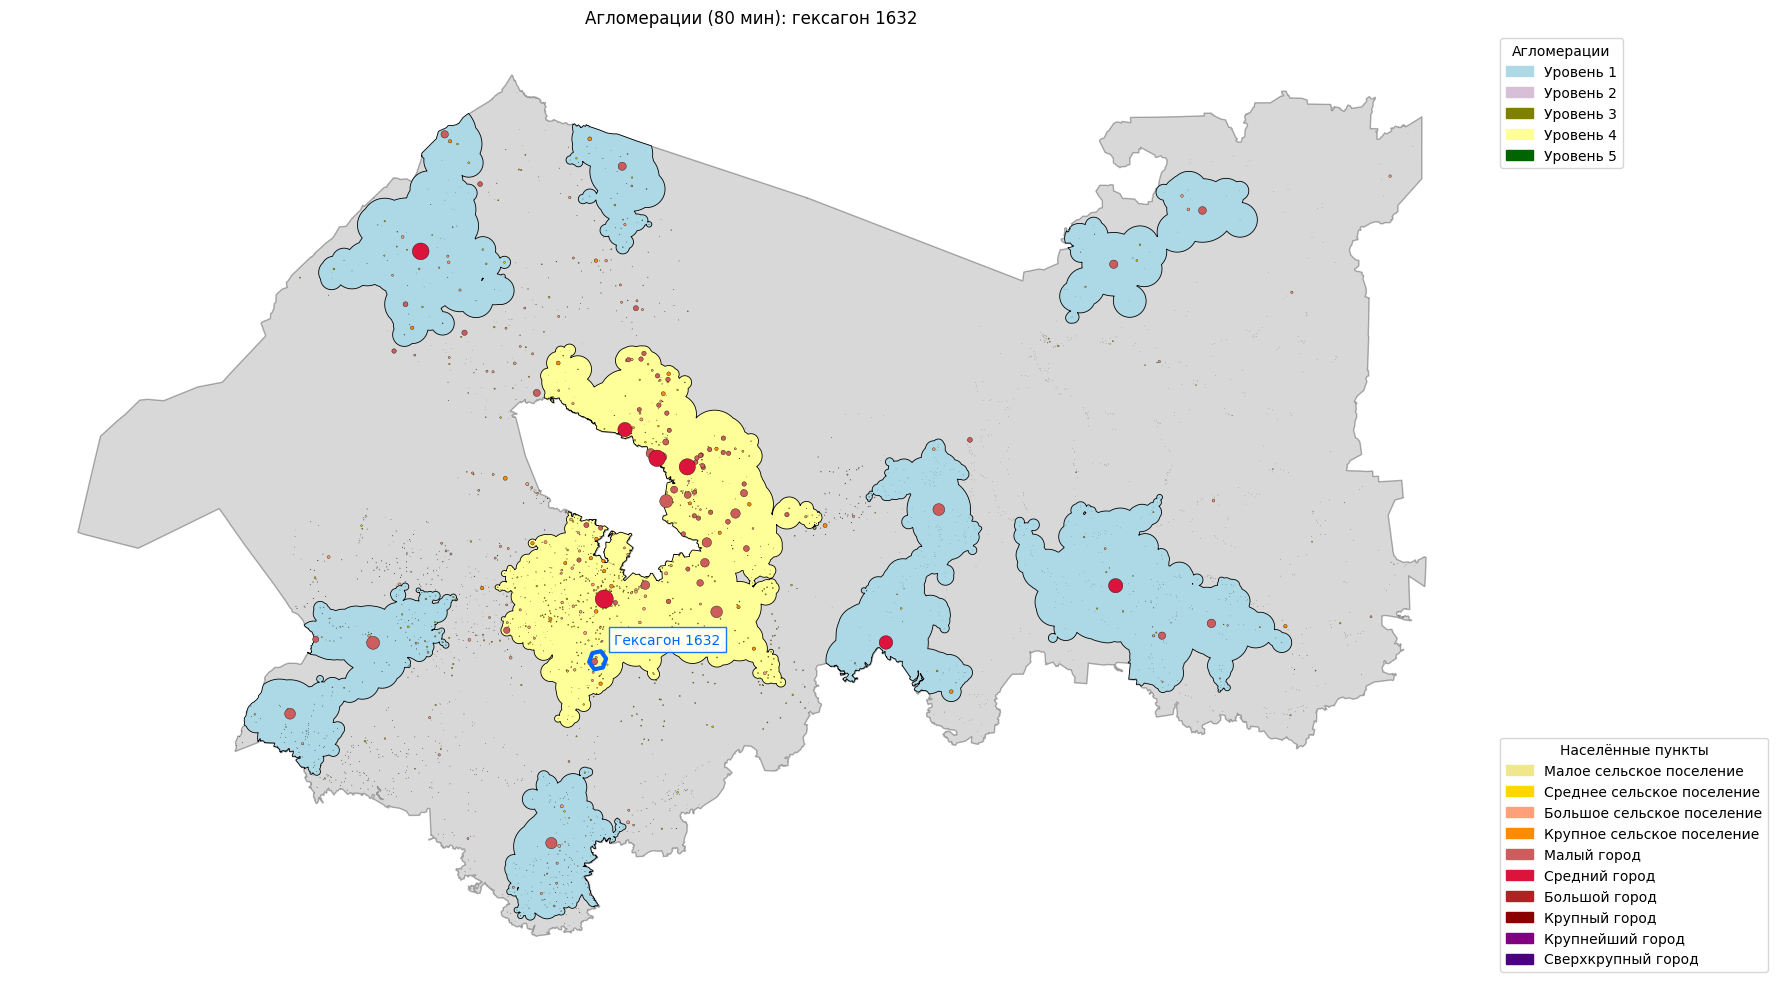

In [23]:
# Показываем базовые агломерации и круги населения, рассчитанные в разделах 3–4.
ax = plot_settlement_scheme(
    region_model, population_frame, base_agglomerations,
    title=f'Агломерации ({BASE_TIME} мин): гексагон {HEX_ID}',
)
# Выделяем выбранный гексагон поверх остальных слоёв.
selected_hex = territory.to_crs(region_model.crs)
selected_hex.plot(ax=ax, facecolor='none', edgecolor='#0066ff', linewidth=3, zorder=10)
label_point = selected_hex.geometry.representative_point().iloc[0]
ax.annotate(
    f'Гексагон {HEX_ID}', xy=(label_point.x, label_point.y),
    xytext=(12, 12), textcoords='offset points', color='#0066ff', zorder=11,
    bbox={'facecolor': 'white', 'edgecolor': '#0066ff', 'alpha': 0.9},
)
plt.tight_layout()
plt.show()


### `TerritoryEvaluation.evaluate_territory_location()`
Метод оценивает положение территории в системе расселения.
Сначала он находит населённые пункты в ближнем буфере и выбирает наибольший балл
их размерной категории, затем проверяет расположение территории между центрами.

**Результат:** балл, текстовое пояснение и только заполненные поля пунктов:
`closest_settlement` для положения рядом с одним пунктом или
`closest_settlement1` и `closest_settlement2` для положения между двумя.
Если подходящих пунктов нет, поля пунктов в результат не добавляются.
Оценка помогает сопоставлять площадки по их пространственному положению.


In [24]:
from popframe.method.territory_evaluation import TerritoryEvaluation

# Создаём объект оценки расположения территории в системе расселения.
evaluation = TerritoryEvaluation(region=region_model)
# Рассчитываем оценку и преобразуем результат в таблицу.
location_results = pd.DataFrame(evaluation.evaluate_territory_location(territory))

# Сохраняем полигон и добавляем к нему полученный балл.
territory_scored = territory.copy()
territory_scored['score'] = location_results['score'].to_numpy()
display(location_results)

,territory,score,interpretation,closest_settlement
0,Гексагон 1632,5,Территория находится внутри или непосредственн...,Сиверский


### Территория и населённые пункты вокруг неё
`explore()` показывает выбранный гекс и населённые пункты в пределах 15 км от него.
При наведении на гекс видны название и балл, на точку — название и население пункта.
Карту можно приближать и перемещать.

In [25]:
# Строим окружение шириной 15 км вокруг гекса; в LOCAL_CRS расстояния заданы в метрах.
surroundings = territory.geometry.buffer(15000)
# Выбираем населённые пункты, попадающие в это окружение.
nearby_towns = towns.loc[towns.intersects(surroundings.iloc[0])]

# Создаём интерактивную карту с бордовым полигоном и его оценкой.
m = territory_scored.explore(
    tiles='OpenStreetMap',
    color='#893434',
    tooltip=['name', 'score'],  # Название и балл видны при наведении.
    style_kwds={'fillOpacity': 0.6, 'weight': 2},  # Прозрачность заливки и толщина границы.
)

# Добавляем населённые пункты на ту же карту: m=m передаёт уже созданную карту.
nearby_towns.explore(
    m=m,
    color='#333333',
    tooltip=['name', 'population'],  # При наведении показываем название и население.
    marker_kwds={'radius': 4},  # Размер точек на экране.
    style_kwds={'fillOpacity': 0.8},
)

# Добавляем контур региона из загруженной pickle-модели без заливки.
boundary.explore(m=m, color='#28486d', tooltip=False, style_kwds={'fill': False, 'weight': 2})

# Переводим границы окружения в долготу/широту для настройки масштаба карты.
west, south, east, north = surroundings.to_crs(4326).total_bounds
m.fit_bounds([[south, west], [north, east]])  # Показываем всё окружение целиком.
m  # Последняя строка выводит интерактивную карту под ячейкой.

### Карта оценок всех гексагонов
Применим `evaluate_territory_location()` ко всей сетке, чтобы сравнить территории.
На интерактивной карте используется палитра **RdYlGn**: от красного для низких
положительных баллов через жёлтый к зелёному для высоких. Нулевой балл показан
чёрным. При наведении видны ID гекса и его балл.


In [26]:
from popframe.visualization import explore_territory_scores

# Создаём отдельный слой, в котором будем хранить оценки всех гексов.
hexagons_scored = hexagons.copy()
# Рассчитываем расположение каждой территории сетки.
grid_results = pd.DataFrame(evaluation.evaluate_territory_location(hexagons_scored))
# Переносим баллы в слой в том же порядке, в котором передавали гексы.
hexagons_scored['score'] = grid_results['score'].to_numpy()
# Показываем баллы на карте: RdYlGn для положительных значений, чёрный для нуля.
m = explore_territory_scores(hexagons_scored)
# Добавляем контур региона из загруженной pickle-модели без заливки.
boundary.explore(m=m, color='#28486d', tooltip=False, style_kwds={'fill': False, 'weight': 2})
m


### Профили развития: от лучшего соответствия к худшему
Сравниваем баллы территории по пяти критериям с минимальными требованиями
каждого профиля: жилая застройка, промышленность, рекреация и другие.

**Как читать рейтинг:**
- Чем больше требований выполнено, тем выше профиль.
- При одинаковом числе выполненных требований выше профиль, которому не хватает меньше баллов.
- «Не хватает баллов» — сумма недостающих баллов по невыполненным критериям; меньше — лучше.
- В столбце «Что улучшить» указано, какой балл нужно увеличить и до какого значения.
- Профили с одинаковыми результатами делят место: например, после двух первых мест идёт третье.

Если выполнены все пять требований, профиль соответствует всем заданным критериям.
Ни один профиль не получает отдельного приоритета или понижения в этом рейтинге.

Баллы «Население», «Транспорт», «Экология», «Соц-об» и «Инж инф»
задаются ниже в словаре `criteria` для заданного сценария.


In [27]:
# Задаём баллы по пяти критериям для сравнения профилей развития.
criteria = {'Население': 4, 'Транспорт': 4, 'Экология': 3, 'Соц-об': 3, 'Инж инф': 2}
# Выше профиль с большим числом выполненных требований; при равенстве — с меньшим дефицитом баллов.
ranked_profiles = evaluation.calculate_potential(criteria, detailed=True)
profile_table = pd.DataFrame([
    {
        'Место': row['rank'],
        'Профиль': row['profile'],
        'Выполнено': f"{row['satisfied_criteria']} из {row['total_criteria']}",
        'Не хватает баллов': row['total_deficit'],
        'Что улучшить': '; '.join(
            f"{name}: {criteria[name]:g} → {criteria[name] + missing:g}"
            for name, missing in row['missing_criteria'].items()
        ) or 'Все требования выполнены',
    }
    for row in ranked_profiles
])
display(profile_table.style.hide(axis='index'))


Место,Профиль,Выполнено,Не хватает баллов,Что улучшить
1,Специального назначения,5 из 5,0,Все требования выполнены
1,Транспортная инженерная,5 из 5,0,Все требования выполнены
3,Рекреационная,4 из 5,1,Экология: 3 → 4
4,Промышленная,4 из 5,2,Инж инф: 2 → 4
5,Сельско-хозяйственная,3 из 5,2,Экология: 3 → 4; Инж инф: 2 → 3
6,Жилая застройка - Малоэтажная,3 из 5,3,Экология: 3 → 4; Инж инф: 2 → 4
7,Жилая застройка - Среднеэтажная,3 из 5,4,Экология: 3 → 4; Инж инф: 2 → 5
8,Жилая застройка - ИЖС,2 из 5,3,Экология: 3 → 4; Соц-об: 3 → 4; Инж инф: 2 → 3
9,Общественно-деловая,2 из 5,4,Транспорт: 4 → 5; Экология: 3 → 4; Инж инф: 2 → 4
10,Жилая застройка - Многоэтажная,1 из 5,6,Население: 4 → 5; Транспорт: 4 → 5; Экология: 3 → 4; Инж инф: 2 → 5


## 9. Сохранение результатов
Выполните следующую ячейку, чтобы получить архив **`examples/data/PopFrame_results.zip`**.
В нём находятся пространственные слои GeoJSON и таблицы CSV.


In [28]:
from zipfile import ZIP_DEFLATED, ZipFile
from IPython.display import FileLink, display

archive_path = DATA_DIR / 'PopFrame_results.zip'
with ZipFile(archive_path, mode='w', compression=ZIP_DEFLATED) as archive:
    for filename, layer in {
        'agglomerations_base': base_agglomerations,
        'agglomerations_population': population_agglomerations,
        'agglomerations_time': time_agglomerations,
        'anchor_boundaries': anchor_boundaries,
        'anchor_boundaries_time': anchor_boundaries_scenario,
        'territory_location': territory_scored,
        'hexagons': hexagons_scored,
    }.items():
        archive.writestr(f'{filename}.geojson', layer.to_crs(4326).to_json())

    for filename, csv in {
        'scenario_summary': scenario_summary.to_csv(),
        'town_status': status_comparison.to_csv(index_label='town_id'),
        'territory_location': location_results.to_csv(index=False),
        'development_profiles': profile_table.to_csv(index=False),
    }.items():
        archive.writestr(f'{filename}.csv', csv.encode('utf-8-sig'))

display(FileLink(str(archive_path)))


/home/mvin/PopFrame-1/examples/data/PopFrame_results.zip